# Background, Lighting & Image-Quality Robustness

COMP7015 Group Project – Topic 1: Plant Disease Classification. This notebook investigates robustness beyond the clean test set (Sections 16–22): the same test leaves under changed background, colour, lighting and image quality; the ViT retrained on grayscale and background-removed photos; the same leaf on different backgrounds; where the models look; training with random backgrounds as a countermeasure; field photos; and how well the models know when they are wrong. It ends with the results summary (Section 23) and the discussion (Section 24) of these results.

Run `01_classification.ipynb` first: it prepares the data, trains and selects the models (Sections 1–13). The shared code lives in the `plantdisease/` package. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score

from plantdisease.config import (
    DATA_CONFIG,
    PLANTDOC_CONFIG,
    SHORT_NAMES,
    TRAIN_CONFIG,
    out_path,
)
from plantdisease.data.backgrounds import make_background_tests, make_test_variants
from plantdisease.data.dataset import prepare
from plantdisease.data.download import field_records
from plantdisease.data.images import build_cache
from plantdisease.data.loaders import make_loader
from plantdisease.evaluate import (
    compare_seeds,
    comparison_table,
    expected_calibration_error,
    field_table,
    mean_sd,
    per_class_f1,
    per_class_recall,
    risk_coverage,
    seed_scores,
    stable_errors,
)
from plantdisease.experiments import (
    COUNTERMEASURES,
    INPUT_TRAINING,
    config_of,
    derived_names,
    load_final_models,
    suffix_label,
)
from plantdisease.gradcam import leaf_share_table
from plantdisease.plots import finish, grouped_bars, mean_curve, seed_bars, show_batch
from plantdisease.predictions import predict_labels, predict_probs
from plantdisease.train import load_history, run, train_dataset

# selected on the validation set (01_classification.ipynb, Sections 9.3 and 10.3)
BEST_CNN, BEST_RESNET, BEST_VIT = load_final_models()
FINAL_MODELS = [BEST_CNN, BEST_RESNET, BEST_VIT]
data = prepare()  # leaf-group split of Sections 3-5, rebuilt from the image cache
# models whose Grad-CAM leaf share is measured (Sections 19, 20.4): all three
CAM_MODELS = FINAL_MODELS

## 16. Robustness on the Same Test Leaves

PlantVillage photos are taken under controlled conditions: one leaf, a plain background and even lighting. Real field photos are not. We evaluate every final model and seed on **the same test leaves** under these transformations:

| Test variant | Question |
|---|---|
| **background removed** (PlantVillage `raw/segmented`, leaf on black) | Does the model rely on the leaf or on the background? The backgrounds differ between the classes (`01_classification.ipynb`, Section 4), so a model can learn the background instead of the leaf. |
| **grayscale** | How much does the model rely on colour (yellowing, brown lesions, mould) versus shape and texture? |
| **darker (×0.6)** | Robustness to poor lighting |
| **blur (Gaussian, σ = 2)** | Robustness to out-of-focus photos |
| **noise (σ = 20 grey levels)** | Robustness to sensor noise / low light |

None of these variants was seen during training, so a drop measures generalisation beyond the training conditions. Section 17 asks how much of the drop disappears when the ViT is retrained on grayscale or background-removed photos. Sections 18–20 follow the background question: the same leaf on another background, where the models look, and a countermeasure. Section 21 tests photos that were not taken under the training conditions at all.

Scores are the mean ± standard deviation over the three training seeds; the dots in the charts are the individual seeds.

### 16.1 Reference: how much does the background alone tell?

Noyan (2022) reported that a classifier that sees only eight pixels from the border of a PlantVillage photo predicts the class far above chance (49% on 38 classes). The backgrounds differ between the classes (`01_classification.ipynb`, Section 4), so the background may already reveal the class. A random forest sees **only the mean colour of the four image corners** (12 numbers per photo, no leaf). It is trained on the training photos and evaluated on the validation photos (the test photos stay untouched).

Two reference classifiers, which see no image at all, tell what the score means:
- **guessing uniformly:** every validation photo gets one of the four classes at random, each with probability 1/4. The table shows the mean over 100 random draws. Its accuracy is about 25%.
- **always the largest class:** every validation photo gets the class with the most **training** photos (named in the table). Its accuracy equals that class's share of the validation photos. Its macro-F1 is low, because the other three classes are never predicted and get an F1 of 0.

A score far above both means that the background alone predicts the class.

In [2]:
def corner_features(images, size=24):
    # Mean colour of the four image corners: the background only, 12 numbers per photo.
    corners = [
        images[:, :, :size, :size],
        images[:, :, :size, -size:],
        images[:, :, -size:, :size],
        images[:, :, -size:, -size:],
    ]
    return torch.cat([c.float().mean(dim=(2, 3)) for c in corners], dim=1).numpy()


def val_scores(y_pred):
    # Accuracy and macro-F1 on the validation photos.
    return {
        "accuracy": accuracy_score(y_val, y_pred),
        "macro-F1": f1_score(y_val, y_pred, average="macro"),
    }


X_corners, y_all = corner_features(data.images), data.labels.numpy()
y_train, y_val = y_all[data.train_idx], y_all[data.val_idx]
n_classes = len(DATA_CONFIG["classes"])

corner_model = RandomForestClassifier(
    n_estimators=200, random_state=DATA_CONFIG["split_seed"], n_jobs=-1
).fit(X_corners[data.train_idx], y_train)

# guessing uniformly: a random class for every photo, mean over 100 draws
rng_guess = np.random.default_rng(DATA_CONFIG["split_seed"])
uniform = pd.DataFrame(
    [val_scores(rng_guess.integers(0, n_classes, len(y_val))) for _ in range(100)]
).mean()

# always the largest class: the class with the most training photos, for every photo
largest = np.bincount(y_train, minlength=n_classes).argmax()

background_only = pd.DataFrame(
    {
        "four image corners only": val_scores(
            corner_model.predict(X_corners[data.val_idx])
        ),
        "guessing uniformly (reference, mean of 100 draws)": uniform,
        f"always the largest class: {SHORT_NAMES[largest]} (reference)": val_scores(
            np.full(len(y_val), largest)
        ),
    }
).T
background_only.to_csv(out_path("background_only.csv"))
background_only.round(3)

,accuracy,macro-F1
four image corners only,0.821,0.791
"guessing uniformly (reference, mean of 100 draws)",0.251,0.242
always the largest class: Bacterial_spot (reference),0.421,0.148


### 16.2 The test leaves under every condition

Test images with a segmented version: 756 / 756


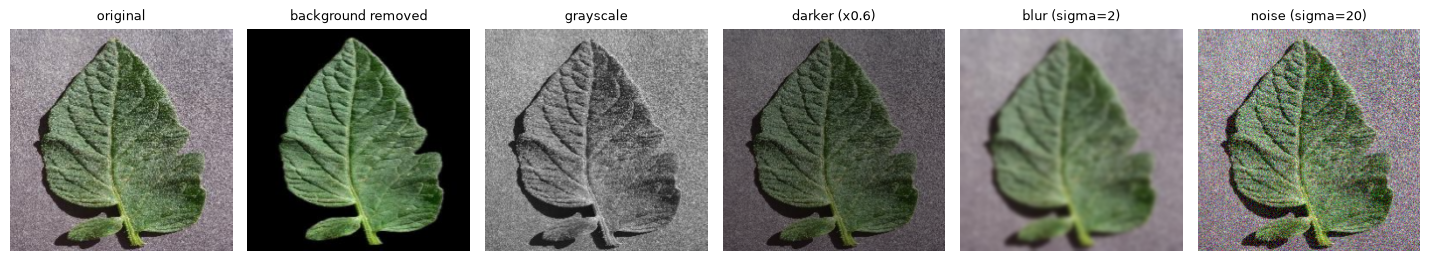

In [3]:
# Test leaves under every condition (plantdisease/data/backgrounds.py: make_test_variants)
test_variants = make_test_variants(data)
VARIANTS, y_rob = test_variants.variants, test_variants.y

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(2.4 * len(VARIANTS), 2.6))
for ax, (variant, imgs) in zip(axes, VARIANTS.items(), strict=True):
    ax.imshow(imgs[0].permute(1, 2, 0))
    ax.set_title(variant, fontsize=9)
    ax.axis("off")
finish()

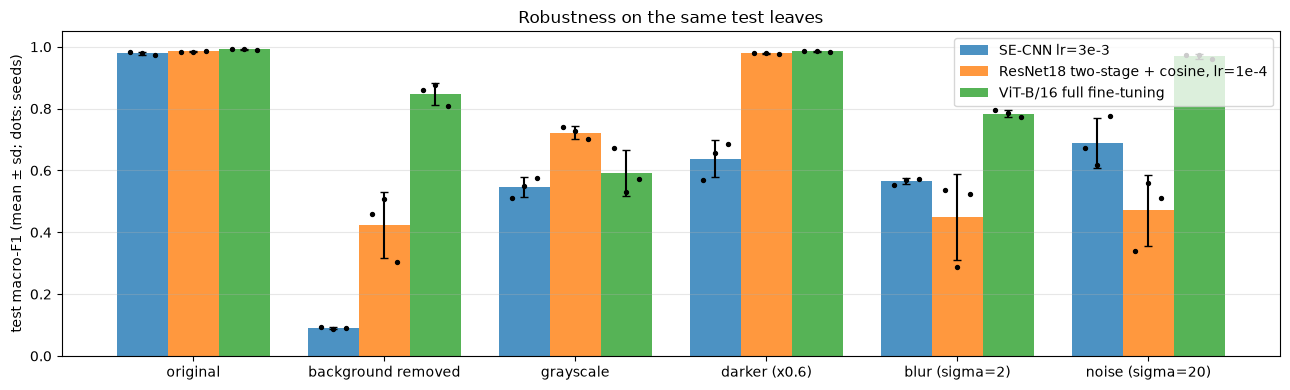

,original,background removed,grayscale,darker (x0.6),blur (sigma=2),noise (sigma=20)
SE-CNN lr=3e-3,0.980 ± 0.005,0.090 ± 0.003,0.546 ± 0.033,0.638 ± 0.060,0.565 ± 0.009,0.689 ± 0.080
"ResNet18 two-stage + cosine, lr=1e-4",0.985 ± 0.001,0.423 ± 0.107,0.723 ± 0.021,0.978 ± 0.002,0.450 ± 0.139,0.471 ± 0.116
ViT-B/16 full fine-tuning,0.992 ± 0.001,0.848 ± 0.035,0.592 ± 0.074,0.985 ± 0.003,0.784 ± 0.011,0.969 ± 0.008


In [4]:
# probabilities and predicted classes: [condition][model] is an array (seeds, N, K) / (seeds, N)
rob_probs = predict_probs(FINAL_MODELS, VARIANTS)
rob_preds = {
    v: {name: p.argmax(-1) for name, p in by_model.items()}
    for v, by_model in rob_probs.items()
}
# macro-F1 of every seed, as a table of models (rows) and conditions (columns)
rob_scores = pd.DataFrame({v: seed_scores(rob_preds[v], y_rob) for v in VARIANTS})

robustness = rob_scores.map(lambda scores: mean_sd(scores, 3))
robustness.to_csv(out_path("robustness.csv"))

fig, ax = plt.subplots(figsize=(13, 4))
seed_bars(ax, rob_scores.T, jitter=True, alpha=0.8)  # one bar group per condition
ax.set_ylabel("test macro-F1 (mean ± sd; dots: seeds)")
ax.set_ylim(0, 1.05)
ax.set_title("Robustness on the same test leaves")
ax.legend(loc="upper right")
ax.grid(axis="y", alpha=0.3)
finish("robustness.png")
robustness

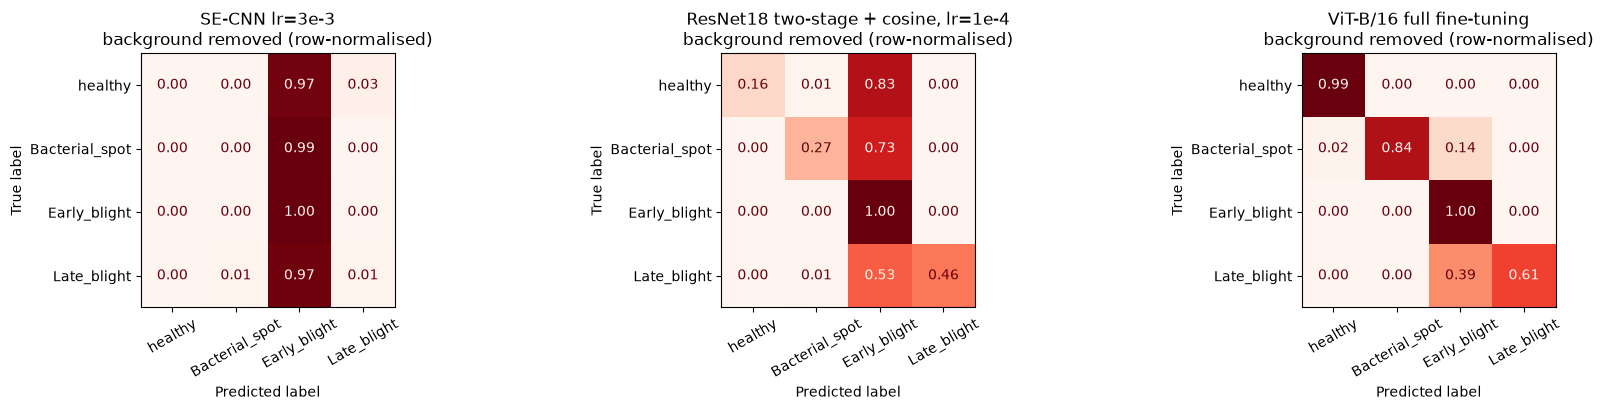

In [5]:
# Background shortcut: share of predictions per class when the background is removed (seeds pooled)
fig, axes = plt.subplots(1, len(FINAL_MODELS), figsize=(6 * len(FINAL_MODELS), 4.2))
for ax, name in zip(axes, FINAL_MODELS, strict=True):
    preds = rob_preds["background removed"][name]  # (seeds, N)
    ConfusionMatrixDisplay.from_predictions(
        np.tile(y_rob, len(preds)),
        preds.ravel(),
        display_labels=SHORT_NAMES,
        normalize="true",
        values_format=".2f",
        cmap="Reds",
        colorbar=False,
        xticks_rotation=30,
        ax=ax,
    )
    ax.set_title(f"{name}\nbackground removed (row-normalised)")
finish("background_removed_confusion.png")

## 17. Retraining on Grayscale and Background-Removed Photos (ViT)

A drop under a test variant mixes two effects: information that is really lost (colour, background) and a **mismatch between training and test input**. The selected ViT configuration is retrained twice more with all seeds: once on grayscale photos and once on background-removed photos. Each version is validated (and its checkpoint selected) on the same input version, then every model is tested on all three versions of the same test leaves. The diagonal of the resulting 3×3 table is "trained and tested on the same input"; the off-diagonal cells are input mismatches.

The grayscale photos are computed from the colour photos (three identical channels); the background-removed photos are PlantVillage's own segmentations, which also cut away some dark leaf regions and the thin leaf edge. A loss on the diagonal therefore measures the value of colour, or of the background together with segmentation artefacts.

Loaded finished run: ViT-B/16 full fine-tuning + grayscale training (seed 62)
Loaded finished run: ViT-B/16 full fine-tuning + grayscale training (seed 63)
Loaded finished run: ViT-B/16 full fine-tuning + grayscale training (seed 64)
Loaded finished run: ViT-B/16 full fine-tuning + background-removed training (seed 62)
Loaded finished run: ViT-B/16 full fine-tuning + background-removed training (seed 63)
Loaded finished run: ViT-B/16 full fine-tuning + background-removed training (seed 64)


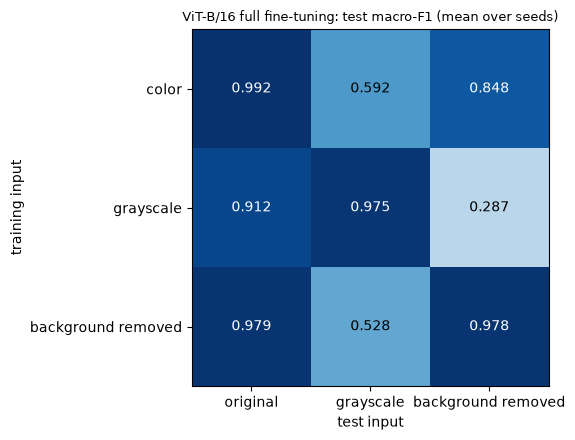

,test: original,test: grayscale,test: background removed
train: color,0.9917 ± 0.0013,0.5925 ± 0.0738,0.8476 ± 0.0352
train: grayscale,0.9118 ± 0.0510,0.9747 ± 0.0072,0.2874 ± 0.0920
train: background removed,0.9786 ± 0.0014,0.5280 ± 0.0712,0.9776 ± 0.0032


In [6]:
INPUT_MODELS = [BEST_VIT, *derived_names(BEST_VIT, INPUT_TRAINING)]
for name in INPUT_MODELS[1:]:
    run(name, data)

TEST_INPUTS = ["original", "grayscale", "background removed"]
input_preds = predict_labels(INPUT_MODELS, {v: VARIANTS[v] for v in TEST_INPUTS})
# macro-F1 of every seed; rows: models (training input), columns: test input
input_scores = pd.DataFrame(
    {v: seed_scores(input_preds[v], y_rob) for v in TEST_INPUTS}
)
training_input = dict(
    zip(INPUT_MODELS, ["color", "grayscale", "background removed"], strict=True)
)

input_grid = input_scores.map(mean_sd).rename(
    index=lambda name: f"train: {training_input[name]}",
    columns=lambda v: f"test: {v}",
)
input_grid.to_csv(out_path("input_training_grid.csv"))

grid = input_scores.map(np.mean).to_numpy()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(grid, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(
            j,
            i,
            f"{grid[i, j]:.3f}",
            ha="center",
            va="center",
            color="white" if grid[i, j] > 0.6 else "black",
        )
ax.set_xticks(range(3), TEST_INPUTS)
ax.set_yticks(range(3), list(training_input.values()))
ax.set_xlabel("test input")
ax.set_ylabel("training input")
ax.set_title(f"{BEST_VIT}: test macro-F1 (mean over seeds)", fontsize=9)
finish("input_training_grid.png")
input_grid

In [7]:
# Matched training and test input: per-class F1 (mean over seeds) and errors that every seed makes
rows = {}
for name, test_input in zip(INPUT_MODELS, TEST_INPUTS, strict=True):
    preds = input_preds[test_input][name]  # (seeds, N)
    per_class = per_class_f1(preds, y_rob)
    rows[f"{training_input[name]} → {test_input}"] = {
        **dict(zip([f"F1 {s}" for s in SHORT_NAMES], per_class, strict=True)),
        **stable_errors(preds, y_rob),
    }
pd.DataFrame(rows).T

,F1 healthy,F1 Bacterial_spot,F1 Early_blight,F1 Late_blight,errors per seed,wrong in every seed,wrong at least once
color → original,1.0,0.998955,0.983065,0.984621,"5, 4, 6",3,8
grayscale → grayscale,0.998878,0.999478,0.951813,0.948519,"16, 18, 10",6,28
background removed → background removed,0.998878,0.999478,0.957709,0.954182,"15, 13, 11",7,18


## 18. Is It the Background? The Same Leaf on Two Backgrounds

Removing the background changes more than the background: black pixels and a sharp mask edge appear, and the segmentation sometimes cuts away dark leaf regions or the thin edge of the leaf. Here **only the background changes**. We take the leaf of every test photo (the **leaf mask** is every pixel that is not black in the segmented photo, small gaps closed, holes filled) and place it on a background tile:

| Test variant | Background | Question |
|---|---|---|
| **same-class background** | corner of another test photo of the **same class** | Control: the same cut-out leaf with a background that fits its label. |
| **other-class background** | corner of a test photo of a **different class** | Do the predictions follow the leaf or the background? |

Both versions contain exactly the same leaf pixels, so a difference between them can only come from the background. A model that learned the background predicts the class of the background photo in the second version. The tile is a 32 × 32 corner of another test photo without leaf pixels, mirrored and repeated over the image. We report macro-F1 and the **share of predictions that equal the class of the background photo**. Leaf masks, corner tiles and the composed images are built by `make_background_tests` in `plantdisease/data/backgrounds.py`.

0 of 756 test photos have an empty mask and stay unchanged
755 of 756 test photos have a leaf-free corner


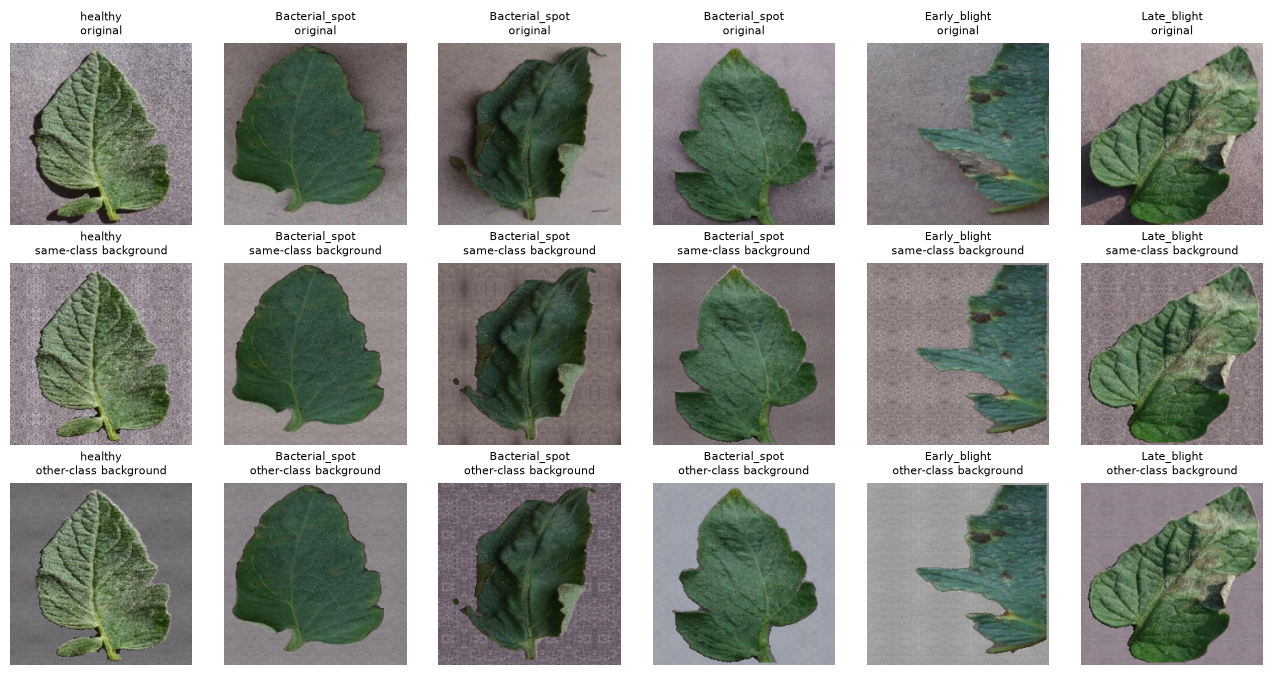

In [8]:
# leaf masks, the same leaves on other backgrounds and the class of each background photo
bg = make_background_tests(test_variants)
BACKGROUND_TESTS, DONOR_CLASS = bg.tests, bg.donor_class
ALL_TESTS = {**VARIANTS, **BACKGROUND_TESTS}  # every test version of the same leaves

# Examples: original photo, same leaf on a background of its own class, on a background of another class
fig, axes = plt.subplots(3, 6, figsize=(13, 6.8))
for col, i in enumerate(np.linspace(0, len(y_rob) - 1, 6).astype(int)):
    for row, (title, imgs) in enumerate(
        {"original": test_variants.original, **BACKGROUND_TESTS}.items()
    ):
        axes[row, col].imshow(imgs[i].permute(1, 2, 0))
        axes[row, col].set_title(f"{SHORT_NAMES[y_rob[i]]}\n{title}", fontsize=8)
        axes[row, col].axis("off")
finish()

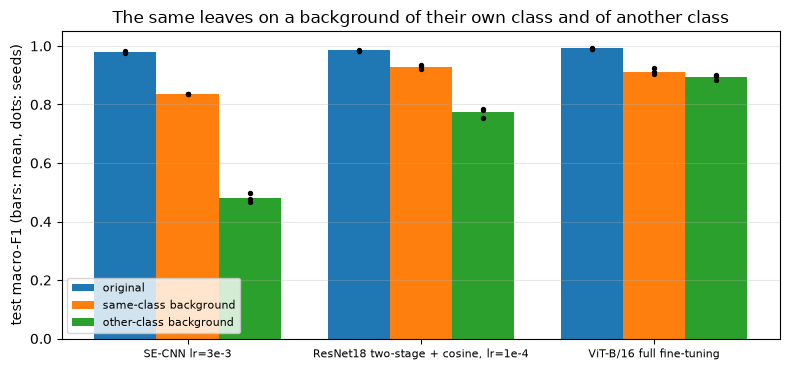

,model,variant,macro-F1,prediction = class of the background photo
0,SE-CNN lr=3e-3,same-class background,0.836 ± 0.000,
1,SE-CNN lr=3e-3,other-class background,0.481 ± 0.016,0.250 ± 0.012
2,"ResNet18 two-stage + cosine, lr=1e-4",same-class background,0.930 ± 0.007,
3,"ResNet18 two-stage + cosine, lr=1e-4",other-class background,0.773 ± 0.017,0.124 ± 0.017
4,ViT-B/16 full fine-tuning,same-class background,0.913 ± 0.010,
5,ViT-B/16 full fine-tuning,other-class background,0.894 ± 0.010,0.021 ± 0.005


In [9]:
bg_preds = predict_labels(FINAL_MODELS, BACKGROUND_TESTS)
bg_scores = pd.DataFrame({v: seed_scores(bg_preds[v], y_rob) for v in BACKGROUND_TESTS})
rows = []
for name in FINAL_MODELS:
    for variant in BACKGROUND_TESTS:
        # share of the predictions that are the class of the background photo, for every seed
        follows = (bg_preds[variant][name] == DONOR_CLASS[variant]).mean(1)
        rows.append(
            {
                "model": name,
                "variant": variant,
                "macro-F1": mean_sd(bg_scores[variant][name], 3),
                "prediction = class of the background photo": (
                    mean_sd(follows, 3) if variant == "other-class background" else ""
                ),
            }
        )
background_tests = pd.DataFrame(rows)
background_tests.to_csv(out_path("background_swap_tests.csv"), index=False)

# one bar group per model: the original photos and the two backgrounds
scores_of = pd.concat([rob_scores[["original"]], bg_scores], axis=1)
fig, ax = plt.subplots(figsize=(8, 3.8))
seed_bars(ax, scores_of, errorbars=False)
ax.tick_params(axis="x", labelsize=8)
ax.set_ylabel("test macro-F1 (bars: mean, dots: seeds)")
ax.set_ylim(0, 1.05)
ax.set_title("The same leaves on a background of their own class and of another class")
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="y", alpha=0.3)
finish("background_swap_tests.png")
background_tests

In [10]:
# Same leaf, only the background differs: other-class minus same-class background (same seed)
rows = []
donor = DONOR_CLASS["other-class background"]
for name in FINAL_MODELS:
    preds = bg_preds["other-class background"][name]  # (seeds, N)
    row = {
        "model": name,
        **compare_seeds(
            bg_scores["other-class background"][name],
            bg_scores["same-class background"][name],
        ),
    }
    for c, short in enumerate(SHORT_NAMES):  # which background pulls the prediction?
        follows = (preds[:, donor == c] == c).mean(1)  # share of every seed
        row[f"follows a {short} background"] = follows.mean()
    rows.append(row)
same_vs_other = pd.DataFrame(rows).set_index("model")
same_vs_other.to_csv(out_path("background_swap_paired.csv"))
same_vs_other.round(3)

,A - B (mean),A - B (sd),A higher in,follows a healthy background,follows a Bacterial_spot background,follows a Early_blight background,follows a Late_blight background
model,,,,,,,
SE-CNN lr=3e-3,-0.355,0.016,0 of 3 seeds,0.306,0.126,0.483,0.129
"ResNet18 two-stage + cosine, lr=1e-4",-0.157,0.011,0 of 3 seeds,0.390,0.028,0.107,0.034
ViT-B/16 full fine-tuning,-0.019,0.009,0 of 3 seeds,0.017,0.010,0.050,0.011


## 19. Where Do the Models Look? Attention on the Leaf

Section 13.3 of `01_classification.ipynb` showed Grad-CAM maps for six example photos. Here we turn them into one number per model. From the **leaf mask** of Section 18 we compute the **leaf share**: the part of the Grad-CAM weight that lies on the leaf. A map that ignored the leaf would give the leaf's share of the image area (*leaf area share*), so a model that really looks at the leaf has a leaf share clearly above that value. We compute it for the original photos, the photos with the background removed and the same leaves on the background of another class.

The maps come from the pytorch-grad-cam library (`plantdisease/gradcam.py`). This includes the ViT: its 196 patch tokens of the last encoder block are reshaped to a 14 × 14 grid (`01_classification.ipynb`, Section 13.3).

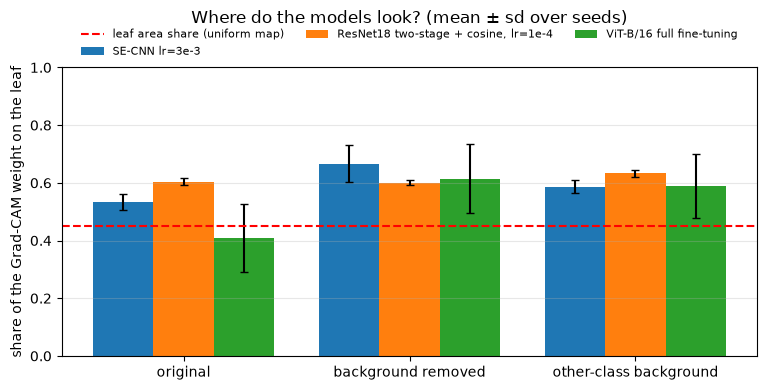

leaf share  \
model                                condition                            
SE-CNN lr=3e-3                       original                     0.534   
                                     background removed           0.667   
                                     other-class background       0.586   
ResNet18 two-stage + cosine, lr=1e-4 original                     0.605   
                                     background removed           0.601   
                                     other-class background       0.633   
ViT-B/16 full fine-tuning            original                     0.409   
                                     background removed           0.615   
                                     other-class background       0.589   

                                                                sd  \
model                                condition                       
SE-CNN lr=3e-3                       original                0.029   
                                     background removed      0.064   
                                     other-class background  0.022   
ResNet18 two-stage + cosine, lr=1e-4 original                0.011   
                                     background removed      0.008   
                                     other-class background  0.013   
ViT-B/16 full fine-tuning            original                0.117   
                                     background removed      0.121   
                                     other-class background  0.111   

                                                             leaf area share  
model                                condition                                
SE-CNN lr=3e-3                       original                           0.45  
                                     background removed                 0.45  
                                     other-class background             0.45  
ResNet18 two-stage + cosine, lr=1e-4 original                           0.45  
                                     background removed                 0.45  
                                     other-class background             0.45  
ViT-B/16 full fine-tuning            original                           0.45  
                                     background removed                 0.45  
                                     other-class background             0.45

In [11]:
leaf_attention_table = leaf_share_table(CAM_MODELS, ALL_TESTS, bg.masks)
leaf_attention_table.to_csv(out_path("leaf_attention.csv"))

# one bar group per condition, one bar per model
attention_conditions = list(leaf_attention_table.loc[BEST_CNN].index)
by_model = leaf_attention_table.unstack("model").loc[attention_conditions]
fig, ax = plt.subplots(figsize=(8, 4))
grouped_bars(ax, by_model["leaf share"][CAM_MODELS], yerr=by_model["sd"][CAM_MODELS])
# the leaf area share is the same for every model and condition (same test leaves)
ax.axhline(
    leaf_attention_table["leaf area share"].iloc[0],
    color="red",
    linestyle="--",
    label="leaf area share (uniform map)",
)
ax.set_ylim(0, 1)
ax.set_ylabel("share of the Grad-CAM weight on the leaf")
ax.set_title("Where do the models look? (mean ± sd over seeds)", pad=32)
ax.legend(
    loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8, frameon=False
)
ax.grid(axis="y", alpha=0.3)
finish("leaf_attention.png")
leaf_attention_table.round(3)

## 20. Countermeasure: Training with Random Backgrounds

The backgrounds differ between the classes, so in the training data the background carries information about the label. As a countermeasure, **the background behind the leaf is replaced by a random one during training**:

| Model | Training | Purpose |
|---|---|---|
| **baseline** | unchanged | reference |
| **countermeasure** | with probability 0.5 everything outside the leaf mask becomes black, a solid colour, a gradient, smooth noise or a leaf-free corner tile of another training photo | the background no longer tells the class |
| **control** | the same cut-out leaves, but the background tile always comes from a photo of the same class | separates label-free backgrounds from seeing cut-out leaves |

The leaf masks come from the segmented photos; photos with an empty mask stay unchanged. The swap is an additional augmentation before the usual ones. The selected CNN, ResNet18 and ViT keep all hyper-parameters, the split, the seeds, early stopping and the checkpoint selection (clean validation macro-F1). The tests are those of Section 18, background removed and diagonal stripes, a background type that never occurs in training. Black is a training background, so "background removed" is not unseen for the countermeasure models.

### 20.1 Leaf masks and the background augmentation

A configuration can carry two optional settings, `background_swap` (the swap probability) and `class_matched_background`. With them, `train_dataset` (`plantdisease/train.py`) uses `BackgroundSwapDataset` (`plantdisease/data/backgrounds.py`); without them nothing changes.

0 of 5045 photos have no segmented version


Leaf masks cover 45% of the image on average | 0 of 5045 photos have an empty or missing mask and are never changed


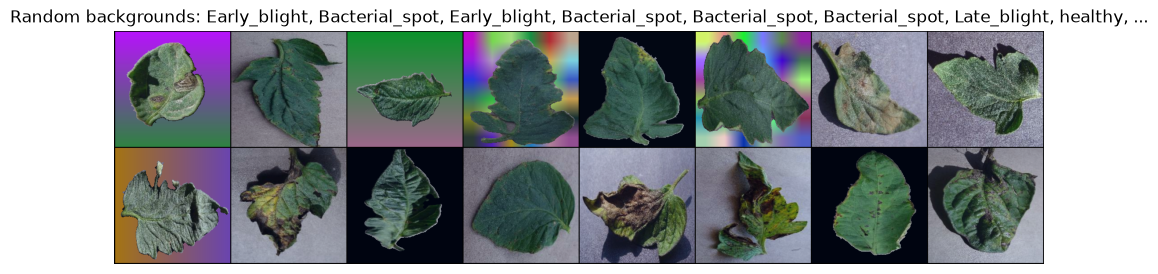

In [12]:
# Visualise training images with random backgrounds (the training set of a countermeasure run)
swap = config_of(f"{BEST_RESNET} + random backgrounds")
x, y = next(iter(make_loader(train_dataset(swap, data), 16, seed=0)))
show_batch(x, y, "Random backgrounds")

### 20.2 Training the countermeasure models

Each selected model is trained twice more with all training seeds: with **random backgrounds** (the countermeasure) and with **class-matched backgrounds** (the control).

In [13]:
# every final model with its countermeasure ('<model> + random backgrounds') and its control
# ('<model> + class-matched backgrounds'); the recipes come from plantdisease/experiments.py: config_of
GROUPS = {base: [base, *derived_names(base, COUNTERMEASURES)] for base in FINAL_MODELS}
for group in GROUPS.values():
    for name in group[1:]:
        run(name, data)

Loaded finished run: SE-CNN lr=3e-3 + random backgrounds (seed 62)
Loaded finished run: SE-CNN lr=3e-3 + random backgrounds (seed 63)
Loaded finished run: SE-CNN lr=3e-3 + random backgrounds (seed 64)
Loaded finished run: SE-CNN lr=3e-3 + class-matched backgrounds (seed 62)
Loaded finished run: SE-CNN lr=3e-3 + class-matched backgrounds (seed 63)
Loaded finished run: SE-CNN lr=3e-3 + class-matched backgrounds (seed 64)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 + random backgrounds (seed 62)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 + random backgrounds (seed 63)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 + random backgrounds (seed 64)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 + class-matched backgrounds (seed 62)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 + class-matched backgrounds (seed 63)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 + class-matched backgrounds (seed 64)
Loaded finished run: V

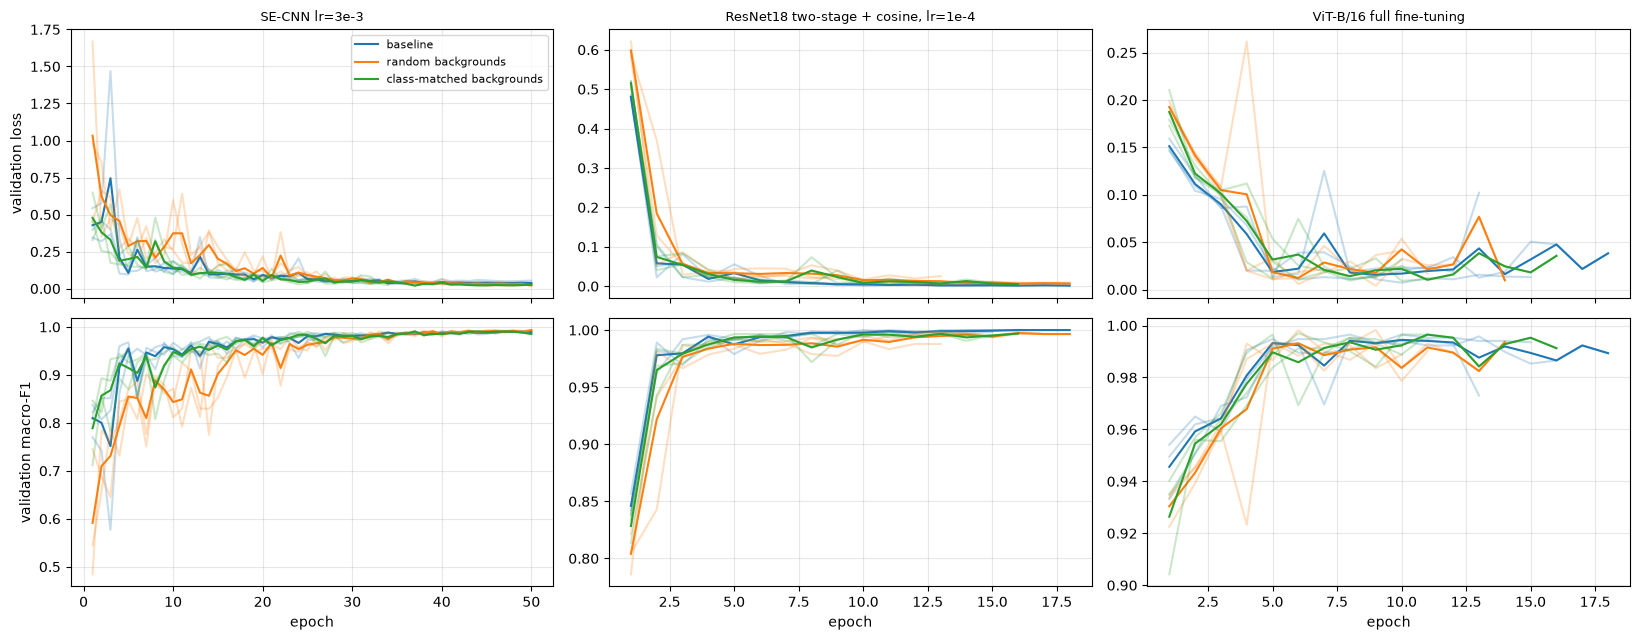

In [14]:
# Validation curves of the baselines, countermeasures and controls (thin: seeds, thick: mean)
fig, axes = plt.subplots(
    2, len(FINAL_MODELS), figsize=(5.5 * len(FINAL_MODELS), 6.5), sharex="col"
)
for col, (base, group) in enumerate(GROUPS.items()):
    for k, name in enumerate(group):
        label = suffix_label(name, base)
        histories_of = [load_history(name, seed) for seed in TRAIN_CONFIG["seeds"]]
        for row, key in enumerate(("val_loss", "val_f1")):
            # values: (seeds, epochs), NaN after a seed stopped early
            epochs, mean, _, values = mean_curve(histories_of, key)
            axes[row, col].plot(epochs, values.T, color=f"C{k}", alpha=0.25)
            axes[row, col].plot(epochs, mean, color=f"C{k}", label=label)
    axes[0, col].set_title(base, fontsize=9)
    axes[1, col].set_xlabel("epoch")
axes[0, 0].set_ylabel("validation loss")
axes[1, 0].set_ylabel("validation macro-F1")
for ax in axes.ravel():
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
finish("countermeasure_curves.png")

### 20.3 Does the countermeasure help? The same leaves on different backgrounds

Every model is tested on the same test leaves in five conditions:

| Condition | What changes | Question |
|---|---|---|
| **original** | nothing | Does the countermeasure cost accuracy on clean photos? |
| **new background (stripes)** | the background, a type never used in training | Does the model cope with an unseen background? |
| **same-class / other-class background** | only the background (Section 18) | Do the predictions follow the leaf and no longer the background? |
| **background removed** | black background | Secondary check, because black is a training background. |

Each architecture appears as **baseline**, **countermeasure** (random backgrounds) and **control** (class-matched backgrounds). The table gives the macro-F1 (mean ± sd over the seeds). Countermeasure and control use the same seeds as their baseline, so the second table compares them seed by seed: the mean and sd of the difference and in how many seeds the new model is higher.

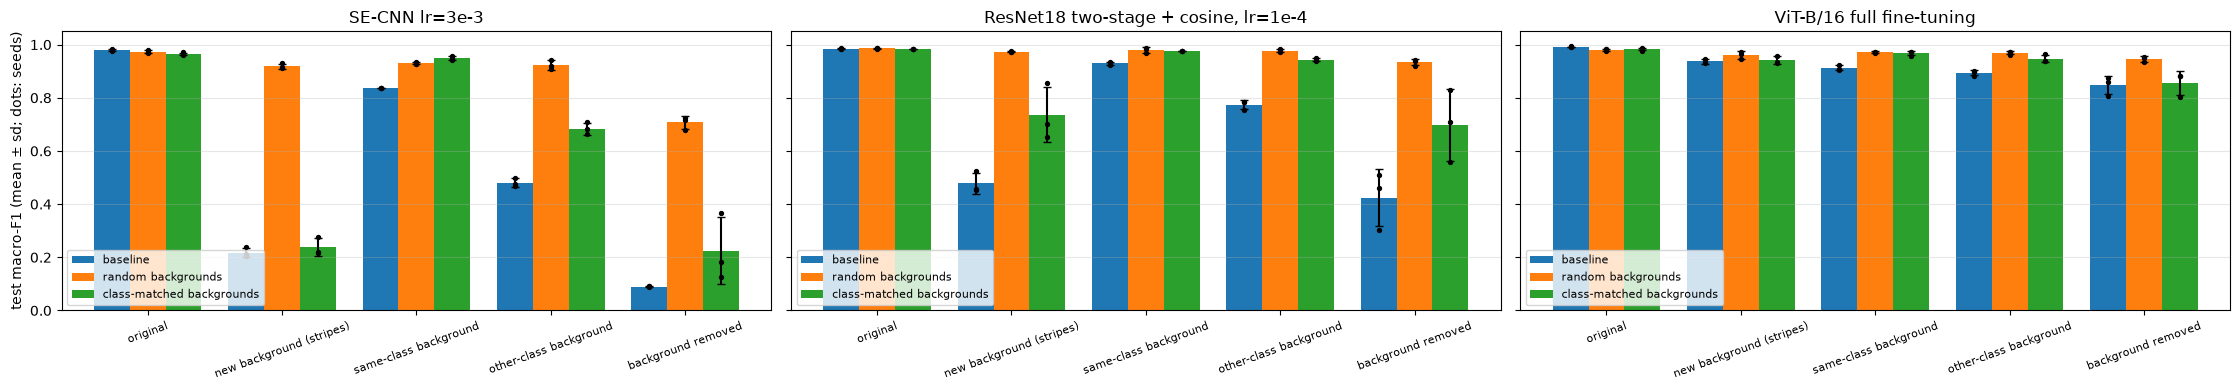

,original,new background (stripes),same-class background,other-class background,background removed
SE-CNN lr=3e-3,0.980 ± 0.005,0.218 ± 0.018,0.836 ± 0.000,0.481 ± 0.016,0.090 ± 0.003
SE-CNN lr=3e-3 + random backgrounds,0.974 ± 0.005,0.919 ± 0.010,0.930 ± 0.005,0.924 ± 0.018,0.708 ± 0.024
SE-CNN lr=3e-3 + class-matched backgrounds,0.966 ± 0.005,0.238 ± 0.033,0.948 ± 0.007,0.684 ± 0.023,0.225 ± 0.126
"ResNet18 two-stage + cosine, lr=1e-4",0.985 ± 0.001,0.479 ± 0.039,0.930 ± 0.007,0.773 ± 0.017,0.423 ± 0.107
"ResNet18 two-stage + cosine, lr=1e-4 + random backgrounds",0.986 ± 0.002,0.973 ± 0.002,0.980 ± 0.009,0.978 ± 0.006,0.933 ± 0.011
"ResNet18 two-stage + cosine, lr=1e-4 + class-matched backgrounds",0.983 ± 0.001,0.737 ± 0.105,0.977 ± 0.001,0.944 ± 0.007,0.699 ± 0.136
ViT-B/16 full fine-tuning,0.992 ± 0.001,0.937 ± 0.008,0.913 ± 0.010,0.894 ± 0.010,0.848 ± 0.035
ViT-B/16 full fine-tuning + random backgrounds,0.981 ± 0.004,0.961 ± 0.013,0.971 ± 0.004,0.969 ± 0.006,0.946 ± 0.011
ViT-B/16 full fine-tuning + class-matched backgrounds,0.983 ± 0.005,0.941 ± 0.015,0.968 ± 0.008,0.948 ± 0.014,0.856 ± 0.045


In [15]:
EVAL_VARIANTS = {
    "original": VARIANTS["original"],
    "new background (stripes)": bg.stripes,
    **BACKGROUND_TESTS,
    "background removed": VARIANTS["background removed"],
}

# every final model, followed by its countermeasure and control
compared = [name for group in GROUPS.values() for name in group]
# predicted classes: [condition][model] is (seeds, N)
variant_preds = predict_labels(compared, EVAL_VARIANTS)
# macro-F1 of every seed; rows: models, columns: conditions
seed_f1 = pd.DataFrame({v: seed_scores(variant_preds[v], y_rob) for v in EVAL_VARIANTS})

countermeasure_table = seed_f1.map(lambda scores: mean_sd(scores, 3))
countermeasure_table.to_csv(out_path("countermeasure_results.csv"))

fig, axes = plt.subplots(
    1, len(FINAL_MODELS), figsize=(7.5 * len(FINAL_MODELS), 4), sharey=True
)
for ax, (base, group) in zip(axes, GROUPS.items(), strict=True):
    # one bar group per condition; bars: baseline, countermeasure, control
    labels = [suffix_label(name, base) for name in group]
    scores = seed_f1.loc[group].set_axis(labels)
    seed_bars(ax, scores.T)
    ax.tick_params(axis="x", labelrotation=20, labelsize=8)
    ax.set_title(base)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("test macro-F1 (mean ± sd; dots: seeds)")
finish("countermeasure_results.png")
countermeasure_table

In [16]:
# Countermeasure / control minus baseline, seed by seed, in every condition
# (countermeasure or control, its baseline); also used for the field photos (Section 21)
pairs = [(name, base) for base, group in GROUPS.items() for name in group[1:]]
countermeasure_comparison = pd.concat(
    {v: comparison_table(pairs, seed_f1[v]) for v in EVAL_VARIANTS}, names=["condition"]
).droplevel(1)
countermeasure_comparison.to_csv(out_path("countermeasure_comparison.csv"))
countermeasure_comparison.round(4)

,model,baseline,A - B (mean),A - B (sd),A higher in
condition,,,,,
original,SE-CNN lr=3e-3 + random backgrounds,SE-CNN lr=3e-3,-0.0058,0.0042,0 of 3 seeds
original,SE-CNN lr=3e-3 + class-matched backgrounds,SE-CNN lr=3e-3,-0.0139,0.0078,0 of 3 seeds
original,"ResNet18 two-stage + cosine, lr=1e-4 + random ...","ResNet18 two-stage + cosine, lr=1e-4",0.0012,0.0010,3 of 3 seeds
original,"ResNet18 two-stage + cosine, lr=1e-4 + class-m...","ResNet18 two-stage + cosine, lr=1e-4",-0.0017,0.0000,0 of 3 seeds
original,ViT-B/16 full fine-tuning + random backgrounds,ViT-B/16 full fine-tuning,-0.0102,0.0039,0 of 3 seeds
original,ViT-B/16 full fine-tuning + class-matched back...,ViT-B/16 full fine-tuning,-0.0090,0.0040,0 of 3 seeds
new background (stripes),SE-CNN lr=3e-3 + random backgrounds,SE-CNN lr=3e-3,0.7011,0.0076,3 of 3 seeds
new background (stripes),SE-CNN lr=3e-3 + class-matched backgrounds,SE-CNN lr=3e-3,0.0201,0.0169,3 of 3 seeds
new background (stripes),"ResNet18 two-stage + cosine, lr=1e-4 + random ...","ResNet18 two-stage + cosine, lr=1e-4",0.4941,0.0403,3 of 3 seeds


In [17]:
# Do the predictions follow the leaf or the background? (other-class background, mean ± sd over seeds)
condition = "other-class background"
targets = {
    "prediction = class of the leaf": y_rob,
    "prediction = class of the background photo": DONOR_CLASS[condition],
}
following = pd.DataFrame(
    {
        column: [
            mean_sd((variant_preds[condition][name] == target).mean(1), 3)
            for name in compared
        ]
        for column, target in targets.items()
    },
    index=compared,
)
following.to_csv(out_path("countermeasure_background_following.csv"))
following

,prediction = class of the leaf,prediction = class of the background photo
SE-CNN lr=3e-3,0.507 ± 0.015,0.250 ± 0.012
SE-CNN lr=3e-3 + random backgrounds,0.940 ± 0.015,0.017 ± 0.008
SE-CNN lr=3e-3 + class-matched backgrounds,0.720 ± 0.010,0.094 ± 0.006
"ResNet18 two-stage + cosine, lr=1e-4",0.791 ± 0.020,0.124 ± 0.017
"ResNet18 two-stage + cosine, lr=1e-4 + random backgrounds",0.982 ± 0.005,0.006 ± 0.002
"ResNet18 two-stage + cosine, lr=1e-4 + class-matched backgrounds",0.954 ± 0.005,0.021 ± 0.004
ViT-B/16 full fine-tuning,0.914 ± 0.008,0.021 ± 0.005
ViT-B/16 full fine-tuning + random backgrounds,0.976 ± 0.004,0.007 ± 0.001
ViT-B/16 full fine-tuning + class-matched backgrounds,0.957 ± 0.012,0.013 ± 0.004


### 20.4 Does the countermeasure move the attention to the leaf?

The leaf share of Section 19 for the countermeasure and control models of the CNN, ResNet18 and the ViT, next to the baselines. If random backgrounds work as intended, the leaf share of the countermeasure models should rise, in particular on backgrounds of another class.

In [18]:
countermeasure_attention = leaf_share_table(
    [name for base in CAM_MODELS for name in GROUPS[base][1:]], ALL_TESTS, bg.masks
)
leaf_attention_all = pd.concat([leaf_attention_table, countermeasure_attention])
leaf_attention_all.to_csv(out_path("leaf_attention_countermeasure.csv"))
leaf_attention_all.round(3)

leaf share  \
model                                              condition                            
SE-CNN lr=3e-3                                     original                     0.534   
                                                   background removed           0.667   
                                                   other-class background       0.586   
ResNet18 two-stage + cosine, lr=1e-4               original                     0.605   
                                                   background removed           0.601   
                                                   other-class background       0.633   
ViT-B/16 full fine-tuning                          original                     0.409   
                                                   background removed           0.615   
                                                   other-class background       0.589   
SE-CNN lr=3e-3 + random backgrounds                original                     0.749   
                                                   background removed           0.861   
                                                   other-class background       0.843   
SE-CNN lr=3e-3 + class-matched backgrounds         original                     0.671   
                                                   background removed           0.521   
                                                   other-class background       0.724   
ResNet18 two-stage + cosine, lr=1e-4 + random b... original                     0.700   
                                                   background removed           0.763   
                                                   other-class background       0.729   
ResNet18 two-stage + cosine, lr=1e-4 + class-ma... original                     0.668   
                                                   background removed           0.717   
                                                   other-class background       0.726   
ViT-B/16 full fine-tuning + random backgrounds     original                     0.598   
                                                   background removed           0.625   
                                                   other-class background       0.672   
ViT-B/16 full fine-tuning + class-matched backg... original                     0.439   
                                                   background removed           0.727   
                                                   other-class background       0.634   

                                                                              sd  \
model                                              condition                       
SE-CNN lr=3e-3                                     original                0.029   
                                                   background removed      0.064   
                                                   other-class background  0.022   
ResNet18 two-stage + cosine, lr=1e-4               original                0.011   
                                                   background removed      0.008   
                                                   other-class background  0.013   
ViT-B/16 full fine-tuning                          original                0.117   
                                                   background removed      0.121   
                                                   other-class background  0.111   
SE-CNN lr=3e-3 + random backgrounds                original                0.013   
                                                   background removed      0.014   
                                                   other-class background  0.010   
SE-CNN lr=3e-3 + class-matched backgrounds         original                0.014   
                                                   background removed      0.075   
                                                   other-class background  0.005   
ResNet18 two-stage + cosine, lr=1e-4 + random b... original      

## 21. Beyond Controlled Photos

Sections 16–20 change the same test leaves. Here the photo changes as a whole: background, light, camera, the individual plants and the disease stage differ together. We evaluate all trained models without retraining: the final models and the countermeasure models of Section 20. A drop shows that a model does not transfer, not why.


### 21.1 Field photos (PlantDoc)

PlantDoc (Singh et al., 2020) collects photos of plants outside the lab: internet photos with several leaves, hands, soil and varying light. We use the four folders that match our classes (`Tomato leaf` is healthy, `Tomato mold leaf` is leaf mold) and **all** their photos as an external test, without retraining. The labels come from web sources and were only checked roughly, so the scores are indicative. **PlantDoc has only 2 spider-mite photos**, so the spider-mite scores are anecdotal; the macro-F1 is computed over the classes that occur, and the per-class recall shows each class separately.

In [19]:
# Downloads only the four tomato folders (train and test) of PlantDoc; finished folders are reused
field_df = field_records(
    {
        PLANTDOC_CONFIG["folders"][c]: class_index
        for class_index, c in enumerate(DATA_CONFIG["classes"])
    }
)
FIELD_AVAILABLE = len(field_df) > 0
print("PlantDoc folders available:", list(field_df["folder"].unique()))

PlantDoc folders available: ['Tomato leaf', 'Tomato leaf bacterial spot', 'Tomato Early blight leaf', 'Tomato leaf late blight']


{'Tomato leaf': 63, 'Tomato leaf bacterial spot': 110, 'Tomato Early blight leaf': 88, 'Tomato leaf late blight': 111}


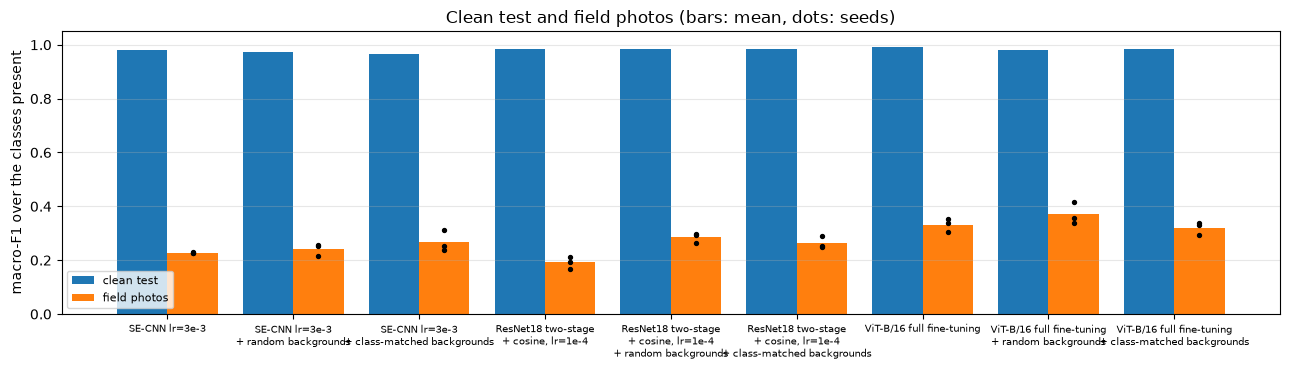

,clean test,field photos,drop
model,,,
SE-CNN lr=3e-3,0.980 ± 0.005,0.229 ± 0.003,0.751086
SE-CNN lr=3e-3 + random backgrounds,0.974 ± 0.005,0.241 ± 0.024,0.732609
SE-CNN lr=3e-3 + class-matched backgrounds,0.966 ± 0.005,0.268 ± 0.040,0.698017
"ResNet18 two-stage + cosine, lr=1e-4",0.985 ± 0.001,0.192 ± 0.022,0.792889
"ResNet18 two-stage + cosine, lr=1e-4 + random backgrounds",0.986 ± 0.002,0.285 ± 0.018,0.700669
"ResNet18 two-stage + cosine, lr=1e-4 + class-matched backgrounds",0.983 ± 0.001,0.264 ± 0.023,0.718790
ViT-B/16 full fine-tuning,0.992 ± 0.001,0.332 ± 0.025,0.660001
ViT-B/16 full fine-tuning + random backgrounds,0.981 ± 0.004,0.370 ± 0.040,0.611208
ViT-B/16 full fine-tuning + class-matched backgrounds,0.983 ± 0.005,0.320 ± 0.023,0.662452


In [20]:
if FIELD_AVAILABLE:
    field_images = build_cache(field_df["path"], "field")
    y_field = field_df["class_index"].to_numpy()
    field_present = np.unique(y_field)
    print(field_df["folder"].value_counts(sort=False).to_dict())

    # every final model with its countermeasure and control, on the clean test and the field photos
    field_preds = predict_labels(
        compared, {"test": data.images[data.test_idx], "field": field_images}
    )
    field_results, field_clean, field_seed = field_table(
        field_preds["test"], field_preds["field"], data.y_test, y_field
    )
    field_results.to_csv(out_path("field_photos.csv"))

    # clean test vs. field photos per model (bars: mean, dots: seeds of the field photos)
    _, ax = plt.subplots(figsize=(13, 3.8))
    scores = pd.DataFrame({"clean test": field_clean, "field photos": field_seed})
    scores = scores.rename(index=lambda name: name.replace(" + ", "\n+ "))
    grouped_bars(ax, scores.map(np.mean), seeds=scores[["field photos"]])
    ax.tick_params(axis="x", labelsize=7)
    ax.set_ylabel("macro-F1 over the classes present")
    ax.set_ylim(0, 1.05)
    ax.set_title("Clean test and field photos (bars: mean, dots: seeds)")
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(axis="y", alpha=0.3)
    finish("field_photos.png")
    display(field_results)
else:
    print("Section 21.1 is skipped: the PlantDoc photos are not available.")

In [21]:
if FIELD_AVAILABLE:
    # Recall per class on the field photos (mean over seeds) and countermeasure vs. baseline

    field_recall = pd.DataFrame.from_dict(
        {
            name: per_class_recall(field_preds["field"][name], y_field, field_present)
            for name in compared
        },
        orient="index",
        columns=[
            f"{SHORT_NAMES[c]} ({(y_field == c).sum()} photos)" for c in field_present
        ],
    )
    field_recall.to_csv(out_path("field_photos_recall.csv"))
    display(field_recall.round(3))
    display(comparison_table(pairs, field_seed).round(4))
else:
    print("Section 21.1 is skipped: the PlantDoc photos are not available.")

,healthy (63 photos),Bacterial_spot (110 photos),Early_blight (88 photos),Late_blight (111 photos)
SE-CNN lr=3e-3,0.037,0.070,0.689,0.363
SE-CNN lr=3e-3 + random backgrounds,0.021,0.209,0.731,0.216
SE-CNN lr=3e-3 + class-matched backgrounds,0.042,0.194,0.625,0.372
"ResNet18 two-stage + cosine, lr=1e-4",0.000,0.076,0.920,0.153
"ResNet18 two-stage + cosine, lr=1e-4 + random backgrounds",0.016,0.206,0.826,0.312
"ResNet18 two-stage + cosine, lr=1e-4 + class-matched backgrounds",0.000,0.136,0.837,0.360
ViT-B/16 full fine-tuning,0.169,0.091,0.955,0.330
ViT-B/16 full fine-tuning + random backgrounds,0.148,0.173,0.920,0.390
ViT-B/16 full fine-tuning + class-matched backgrounds,0.095,0.091,0.962,0.378


,model,baseline,A - B (mean),A - B (sd),A higher in
0,SE-CNN lr=3e-3 + random backgrounds,SE-CNN lr=3e-3,0.0127,0.0230,2 of 3 seeds
1,SE-CNN lr=3e-3 + class-matched backgrounds,SE-CNN lr=3e-3,0.0392,0.0417,3 of 3 seeds
2,"ResNet18 two-stage + cosine, lr=1e-4 + random ...","ResNet18 two-stage + cosine, lr=1e-4",0.0934,0.0293,3 of 3 seeds
3,"ResNet18 two-stage + cosine, lr=1e-4 + class-m...","ResNet18 two-stage + cosine, lr=1e-4",0.0723,0.0160,3 of 3 seeds
4,ViT-B/16 full fine-tuning + random backgrounds,ViT-B/16 full fine-tuning,0.0386,0.0621,3 of 3 seeds
5,ViT-B/16 full fine-tuning + class-matched back...,ViT-B/16 full fine-tuning,-0.0115,0.0433,1 of 3 seeds


## 22. Can the Models Tell When They Are Wrong? Confidence and Abstention

A model that is unsure could hand a photo to an expert instead of guessing. This works only if wrong predictions have a lower confidence than correct ones. We take the highest predicted probability as the **confidence**, sort the test photos by it and let the model **abstain** on the least confident photos. The **risk-coverage curve** shows the accuracy of the photos that are still answered (y axis) against the share of photos that are answered (x axis). A curve that rises quickly when a few photos are left out means that the confidence flags the errors. A flat curve means that the model is as confident when it is wrong as when it is right. We show the curves for the original test images and under the changes of Section 16.

The curves are descriptive: no abstention threshold is chosen on the test set. The table also reports the **expected calibration error** (ECE), the average gap between confidence and accuracy over ten confidence bins.

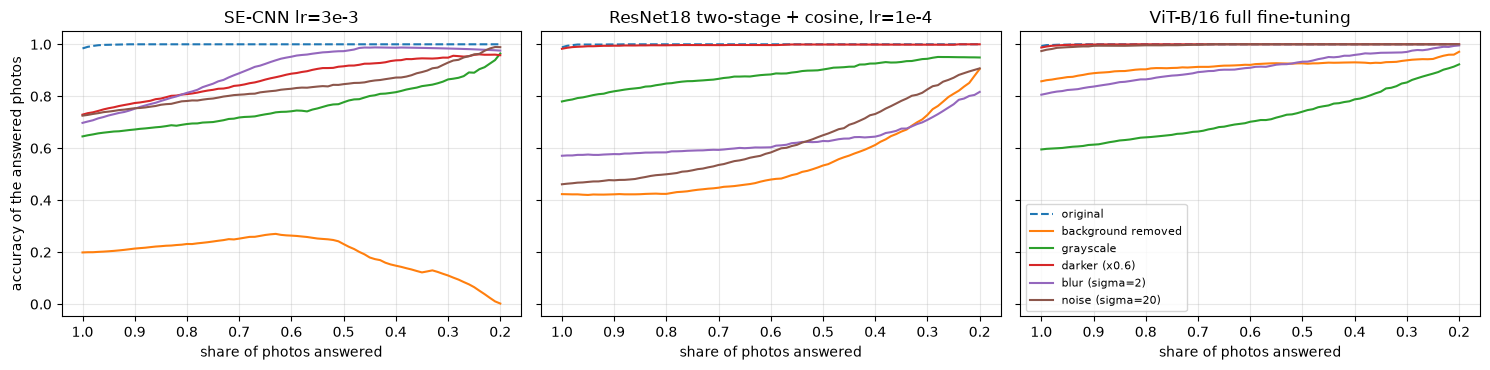

In [22]:
coverages = np.linspace(1.0, 0.2, 81)
fig, axes = plt.subplots(
    1, len(FINAL_MODELS), figsize=(5 * len(FINAL_MODELS), 3.8), sharey=True
)
for ax, name in zip(axes, FINAL_MODELS, strict=True):
    for variant in VARIANTS:
        curve = np.mean(
            [
                risk_coverage(probs, y_rob, coverages)
                for probs in rob_probs[variant][name]  # one array per seed
            ],
            axis=0,
        )
        ax.plot(
            coverages,
            curve,
            label=variant,
            linestyle="--" if variant == "original" else "-",
        )
    ax.set_title(name)
    ax.set_xlabel("share of photos answered")
    ax.invert_xaxis()
    ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy of the answered photos")
axes[-1].legend(loc="lower left", fontsize=8)
finish("risk_coverage.png")

In [23]:
rows = []
for name in FINAL_MODELS:
    for variant in VARIANTS:
        seed_stats = []
        for probs in rob_probs[variant][name]:  # one array (N, K) per seed
            wrong = probs.argmax(1) != y_rob
            least_confident = np.argsort(probs.max(1), kind="stable")[
                : int(0.05 * len(y_rob))
            ]
            seed_stats.append(
                {
                    "errors": wrong.sum(),
                    "accuracy (all photos answered)": 1 - wrong.mean(),
                    "accuracy (95% answered)": risk_coverage(
                        probs, y_rob, np.array([0.95])
                    )[0],
                    "share of errors among the 5% least confident": (
                        wrong[least_confident].sum() / wrong.sum()
                        if wrong.any()
                        else np.nan
                    ),
                    "ECE": expected_calibration_error(probs, y_rob),
                }
            )
        rows.append(
            {
                "model": name,
                "variant": variant,
                **pd.DataFrame(seed_stats).mean().to_dict(),
            }
        )
confidence_table = pd.DataFrame(rows).set_index(["model", "variant"])
confidence_table.to_csv(out_path("confidence_abstention.csv"))
confidence_table.round(3)

errors  \
model                                variant                       
SE-CNN lr=3e-3                       original             12.000   
                                     background removed  605.667   
                                     grayscale           268.000   
                                     darker (x0.6)       204.667   
                                     blur (sigma=2)      228.667   
                                     noise (sigma=20)    207.667   
ResNet18 two-stage + cosine, lr=1e-4 original              8.667   
                                     background removed  436.000   
                                     grayscale           166.333   
                                     darker (x0.6)        13.000   
                                     blur (sigma=2)      324.333   
                                     noise (sigma=20)    407.333   
ViT-B/16 full fine-tuning            original              5.000   
                                     background removed  107.667   
                                     grayscale           306.000   
                                     darker (x0.6)         9.333   
                                     blur (sigma=2)      146.667   
                                     noise (sigma=20)     19.667   

                                                         accuracy (all photos answered)  \
model                                variant                                              
SE-CNN lr=3e-3                       original                                     0.984   
                                     background removed                           0.199   
                                     grayscale                                    0.646   
                                     darker (x0.6)                                0.729   
                                     blur (sigma=2)                               0.698   
                                     noise (sigma=20)                             0.725   
ResNet18 two-stage + cosine, lr=1e-4 original                                     0.989   
                                     background removed                           0.423   
                                     grayscale                                    0.780   
                                     darker (x0.6)                                0.983   
                                     blur (sigma=2)                               0.571   
                                     noise (sigma=20)                             0.461   
ViT-B/16 full fine-tuning            original                                     0.993   
                                     background removed                           0.858   
                                     grayscale                                    0.595   
                                     darker (x0.6)                                0.988   
                                     blur (sigma=2)                               0.806   
                                     noise (sigma=20)                             0.974   

                                                         accuracy (95% answered)  \
model                                variant                                       
SE-CNN lr=3e-3                       original                              0.998   
                                     background removed                    0.203   
                                     grayscale                             0.662   
                                     darker (x0.6)                         0.754   
                                     blur (sigma=2)                        0.726   
                                     noise (sigma=20)                      0.741   
ResNet18 two-stage + cosine, lr=1e-4 original                              0.999   
                                     background removed                    0.420   
                                    

## 23. Results Summary (robustness)

Every table below is read from `OUT_DIR`, where the sections above save them. A missing table means that its section has not run yet. The tables of the data, models and clean test are collected at the end of `01_classification.ipynb`.

In [24]:
import os

from IPython.display import Markdown

TABLES = [
    ("Background alone (Section 16.1)", "background_only.csv"),
    ("Robustness on the same test leaves (Section 16)", "robustness.csv"),
    ("ViT retrained on other inputs (Section 17)", "input_training_grid.csv"),
    ("Same leaf, other background (Section 18)", "background_swap_tests.csv"),
    (
        "Same leaf, other background: paired and per background class (Section 18)",
        "background_swap_paired.csv",
    ),
    ("Attention on the leaf (Sections 19, 20.4)", "leaf_attention_countermeasure.csv"),
    ("Countermeasure (Section 20.3)", "countermeasure_results.csv"),
    (
        "Countermeasure vs. baseline, seed by seed (Section 20.3)",
        "countermeasure_comparison.csv",
    ),
    (
        "Countermeasure: predictions that follow the leaf or the background (Section 20.3)",
        "countermeasure_background_following.csv",
    ),
    ("PlantDoc field photos (Section 21.1)", "field_photos.csv"),
    (
        "PlantDoc field photos: recall per class (Section 21.1)",
        "field_photos_recall.csv",
    ),
    ("Confidence and abstention (Section 22)", "confidence_abstention.csv"),
]

for title, file_name in TABLES:
    display(Markdown(f"**{title}** (`{file_name}`)"))
    path = out_path(file_name)
    if os.path.exists(path):
        display(pd.read_csv(path))
    else:
        display(Markdown("*not available yet*"))

**Background alone (Section 16.1)** (`background_only.csv`)

,Unnamed: 0,accuracy,macro-F1
0,four image corners only,0.821053,0.790958
1,"guessing uniformly (reference, mean of 100 draws)",0.250553,0.242063
2,always the largest class: Bacterial_spot (refe...,0.421053,0.148148


**Robustness on the same test leaves (Section 16)** (`robustness.csv`)

,Unnamed: 0,original,background removed,grayscale,darker (x0.6),blur (sigma=2),noise (sigma=20)
0,SE-CNN lr=3e-3,0.980 ± 0.005,0.090 ± 0.003,0.546 ± 0.033,0.638 ± 0.060,0.565 ± 0.009,0.689 ± 0.080
1,"ResNet18 two-stage + cosine, lr=1e-4",0.985 ± 0.001,0.423 ± 0.107,0.723 ± 0.021,0.978 ± 0.002,0.450 ± 0.139,0.471 ± 0.116
2,ViT-B/16 full fine-tuning,0.992 ± 0.001,0.848 ± 0.035,0.592 ± 0.074,0.985 ± 0.003,0.784 ± 0.011,0.969 ± 0.008


**ViT retrained on other inputs (Section 17)** (`input_training_grid.csv`)

,Unnamed: 0,test: original,test: grayscale,test: background removed
0,train: color,0.9917 ± 0.0013,0.5925 ± 0.0738,0.8476 ± 0.0352
1,train: grayscale,0.9118 ± 0.0510,0.9747 ± 0.0072,0.2874 ± 0.0920
2,train: background removed,0.9786 ± 0.0014,0.5280 ± 0.0712,0.9776 ± 0.0032


... (14 outputs left out)

**PlantDoc field photos: recall per class (Section 21.1)** (`field_photos_recall.csv`)

,Unnamed: 0,healthy (63 photos),Bacterial_spot (110 photos),Early_blight (88 photos),Late_blight (111 photos)
0,SE-CNN lr=3e-3,0.037037,0.069697,0.689394,0.363363
1,SE-CNN lr=3e-3 + random backgrounds,0.021164,0.209091,0.731061,0.216216
2,SE-CNN lr=3e-3 + class-matched backgrounds,0.042328,0.193939,0.625000,0.372372
3,"ResNet18 two-stage + cosine, lr=1e-4",0.000000,0.075758,0.920455,0.153153
4,"ResNet18 two-stage + cosine, lr=1e-4 + random ...",0.015873,0.206061,0.825758,0.312312
5,"ResNet18 two-stage + cosine, lr=1e-4 + class-m...",0.000000,0.136364,0.837121,0.360360
6,ViT-B/16 full fine-tuning,0.169312,0.090909,0.954545,0.330330
7,ViT-B/16 full fine-tuning + random backgrounds,0.148148,0.172727,0.920455,0.390390
8,ViT-B/16 full fine-tuning + class-matched back...,0.095238,0.090909,0.962121,0.378378


**Confidence and abstention (Section 22)** (`confidence_abstention.csv`)

,model,variant,errors,accuracy (all photos answered),accuracy (95% answered),share of errors among the 5% least confident,ECE
0,SE-CNN lr=3e-3,original,12.000000,0.984127,0.998143,0.885185,0.008473
1,SE-CNN lr=3e-3,background removed,605.666667,0.198854,0.203343,0.053934,0.793556
2,SE-CNN lr=3e-3,grayscale,268.000000,0.645503,0.662024,0.096508,0.319810
3,SE-CNN lr=3e-3,darker (x0.6),204.666667,0.729277,0.753946,0.132830,0.210754
4,SE-CNN lr=3e-3,blur (sigma=2),228.666667,0.697531,0.726091,0.135696,0.263173
5,SE-CNN lr=3e-3,noise (sigma=20),207.666667,0.725309,0.740947,0.106656,0.210430
6,"ResNet18 two-stage + cosine, lr=1e-4",original,8.666667,0.988536,0.999071,0.921296,0.008935
7,"ResNet18 two-stage + cosine, lr=1e-4",background removed,436.000000,0.423280,0.420149,0.044174,0.494495
8,"ResNet18 two-stage + cosine, lr=1e-4",grayscale,166.333333,0.779982,0.799907,0.135731,0.146012
9,"ResNet18 two-stage + cosine, lr=1e-4",darker (x0.6),13.000000,0.982804,0.992572,0.561111,0.011606


## 24. Discussion

Section 15 at the end of `01_classification.ipynb` discusses the data, the models and the clean test results. Unless stated otherwise, scores are the macro-F1 on the 756 test photos, given as mean ± sd over the three training seeds. "Higher in k of 3 seeds" compares two models trained with the same seeds. All numbers come from the tables in Section 23.

**In short.** The clean score (0.980–0.992 macro-F1) says little about the models outside the training conditions. The background alone predicts the class, the custom CNN largely follows it, and every model fails on field photos. Training with random backgrounds removes the background shortcut of all three models, at no clean cost for ResNet18 and a small one for the SE-CNN and the ViT. It does not make the models transfer to the field.

### 24.1 Robustness (Sections 16–22)

**Changes to the same test leaves (Section 16).**
- The SE-CNN, trained from scratch, collapses under every change (0.09–0.69). This includes a moderate darkening (×0.6, 0.638) that lies outside its ±10% brightness jitter. Without the background it scores 0.090, far below uniform guessing (about 0.24). With ImageNet pre-training, ResNet18 and the ViT are robust to darkening (0.978, 0.985), and the ViT also to noise (0.969). Blur hurts every model (0.45–0.78), the ViT least. Grayscale hurts every model too (0.55–0.72), ResNet18 least (0.723, against 0.592 for the ViT). Removing the background separates the models most clearly: 0.090 (SE-CNN), 0.423 (ResNet18) and 0.848 (ViT).
- The seed-to-seed variation grows from ±0.001–0.005 on clean photos to ±0.139 (ResNet18, blur), ±0.116 (ResNet18, noise) and ±0.107 (ResNet18, background removed). Seeds that are equally good on clean photos can differ widely under these changes, so the clean score does not predict robustness.
- **Retraining on the changed input (Section 17) removes most of the drop.** A ViT trained and tested on grayscale reaches 0.975 ± 0.007, against 0.992 in colour. Colour is thus worth about 0.02 macro-F1, and the grayscale drop to 0.592 is mostly a mismatch between training and test input. A ViT trained and tested on background-removed photos reaches 0.978 ± 0.003, only 0.014 below the colour model on original photos. **The leaf alone carries almost all the information; the background is a shortcut, not a necessity.** The remaining gap may partly come from the segmentation, which also cuts away some leaf regions. The background-removed model transfers well to original photos (0.979 ± 0.001), but neither retrained model transfers to the other changed input: trained on grayscale and tested on background-removed photos 0.287 ± 0.092, and the other way round 0.528 ± 0.071.

**Leaf or background? (Sections 18, 19).**
- With exactly the same leaf pixels, a background of another class lowers the score of every model in every seed. The SE-CNN falls from 0.836 to 0.481, ResNet18 from 0.930 to 0.773 and the ViT from 0.913 to 0.894 (paired differences −0.355, −0.157 and −0.019, lower in 3 of 3 seeds). The SE-CNN predicts the class of the background photo for 25% of the leaves, ResNet18 for 12% and the ViT for 2%. **The ViT barely follows the background; the two CNNs clearly do.**
- Which background pulls depends on the model. On a background from a **healthy** photo, a diseased leaf is called healthy in 39% of the cases by ResNet18 and 31% by the SE-CNN. The SE-CNN is pulled most by **early-blight** backgrounds (48%). Bacterial-spot and late-blight backgrounds pull much less (13% for the SE-CNN, ≤ 3% for ResNet18). The ViT follows no background class in more than 5% of the cases.
- The same-class control already costs something: 0.980 → 0.836 (SE-CNN), 0.985 → 0.930 (ResNet18), 0.992 → 0.913 (ViT). Cut-out leaves on tiled backgrounds are unfamiliar input in themselves. The background effect is the further drop from the same-class to the other-class background. For the ViT, the unfamiliar composition costs much more (−0.079) than the background class (−0.019).
- **Grad-CAM (Section 19).** The leaf covers 45% of the image. The SE-CNN puts 53% of its Grad-CAM weight on the leaf and ResNet18 60% (59% and 63% on other-class backgrounds). The two CNNs thus look at the leaf a little more than a map that ignores it would. The ViT's map puts only 41% on the leaf, but with a large spread over the seeds (±0.12). This does not fit the ViT's small background effect above. Grad-CAM on the last ViT block (14×14 patch grid) is a coarse and less reliable explanation than for the CNNs, so we trust the behavioural tests more here.

**Countermeasure (Section 20).**
- **ResNet18 + random backgrounds** shows no clean cost: 0.986 ± 0.002 against 0.985 (+0.001 ± 0.001, higher in 3 of 3 seeds). Unseen striped backgrounds go from 0.479 to 0.973 (+0.49) and other-class backgrounds from 0.773 to 0.978 (+0.20), in 3 of 3 seeds. Background removed goes from 0.423 to 0.933, but black is one of the random training backgrounds. The share of predictions that follow the background falls from 12.4% to 0.6%, and the Grad-CAM leaf share rises from 0.60 to 0.70. **For ResNet18, random backgrounds remove the background shortcut without costing clean accuracy.**
- **SE-CNN + random backgrounds** gains the most. Stripes go from 0.218 to 0.919 (+0.70), other-class backgrounds from 0.481 to 0.924 (+0.44) and background removed from 0.090 to 0.708. Background-following falls from 25% to 1.7%, and the leaf share rises from 0.53 to 0.75. The clean cost is small but consistent: 0.974 against 0.980 (−0.006 ± 0.004, lower in 3 of 3 seeds). Without the shortcut, the small model trained from scratch has to learn the disease itself from 3,529 photos.
- **ViT + random backgrounds** starts from a model that barely uses the background, so it gains less: stripes 0.937 → 0.961, other-class backgrounds 0.894 → 0.969, background removed 0.848 → 0.946 (all 3 of 3 seeds). Background-following falls from 2.1% to 0.7%, and the leaf share rises from 0.41 to 0.60. It costs 0.010 ± 0.004 on clean photos (0.981, lower in 3 of 3 seeds), the largest clean cost of the three.
- **The class-matched control** gains much less on unfamiliar backgrounds. On stripes it reaches 0.238 (SE-CNN), 0.737 ± 0.105 (ResNet18) and 0.941 (ViT), against 0.919, 0.973 and 0.961 with random backgrounds. With the background removed it reaches 0.225, 0.699 and 0.856. On other-class backgrounds it does help (0.684, 0.944, 0.948), but less than random backgrounds. Its gain on same-class backgrounds (+0.05 to +0.11) is as large as with random backgrounds, so that part comes from getting used to cut-out leaves. The rest of the gain therefore comes from breaking the link between background and label, not from training on cut-out leaves.

**Beyond controlled photos (Section 21).**
- **PlantDoc field photos** (372 photos: 63 healthy, 110 bacterial spot, 88 early blight, 111 late blight). Macro-F1 falls from at least 0.97 to 0.19–0.37 for every model. ResNet18 (0.192 ± 0.022) and the SE-CNN (0.229 ± 0.003) are no better than uniform guessing. Early blight is recalled most of the time (0.69–0.95 for the final models), healthy almost never (≤ 0.17) and bacterial spot rarely (≤ 0.09). Most field photos thus end up as early blight. The ViT is best among the final models (0.332 ± 0.025), and **ViT + random backgrounds** is best overall (0.370 ± 0.040). Random backgrounds also raise ResNet18 to 0.285 ± 0.018, mainly through better bacterial-spot and late-blight recall. Field photos with several leaves, hands, soil and natural light differ in every respect, and their labels were checked only roughly. No model is usable in the field without field photos in training.

**Confidence and abstention (Section 22).**
- On the clean test the confidence flags the errors. Abstaining on the 5% least confident photos raises the accuracy to 0.998 (SE-CNN) and 0.999 (ResNet18, ViT). These 5% hold 79–92% of the errors, and the ECE is at most 0.009.
- Under the changes of Section 16, the models are **confidently wrong**. The ECE rises to 0.79 (SE-CNN, background removed), 0.49 (ResNet18, background removed), 0.41 (ResNet18, noise) and 0.22 (ViT, grayscale). Abstaining on 5% hardly changes the accuracy: 0.199 → 0.203 (SE-CNN, background removed), 0.571 → 0.576 (ResNet18, blur), 0.595 → 0.604 (ViT, grayscale). The confidence stays useful only where the model stays accurate: ResNet18 and the ViT under darkening and the ViT under noise (ECE ≤ 0.016, 56–82% of the errors in the 5%). Abstention therefore cannot catch the failures that matter most, those under a shift of the input.

### 24.2 Limitations

- **Controlled photos only.** Disease is confounded with background, camera and light. The countermeasure addresses only the background; the PlantDoc results show that the other factors remain.
- **Three seeds on one fixed split.** The standard deviation covers training randomness, not the choice of test leaves. With 756 test photos, clean differences of a few photos are small, even when they are consistent over the seeds.
- **Saturated validation set.** Most recipes tie at 0.99–1.00, and the ablations ran on a single seed, so the choice between tied recipes is partly arbitrary.
- **Data selection.** Only photos with an official leaf id are used. This drops 1,582 photos, most of the greenhouse photos and over half of the late-blight folder, so the late-blight class covers fewer conditions than it could.
- **Segmentation.** The background-removed photos come from PlantVillage's own segmentation, which also cuts away some leaf regions. The leaf masks of Sections 18–20 inherit these errors. The composed images (tiled background, mask edge) are unfamiliar in themselves, as the drop on same-class backgrounds shows.
- **Coverage.** Each change of Section 16 was tested at one strength only. Grad-CAM on the ViT is coarse and varies strongly between seeds, so its leaf share is weak evidence. PlantDoc has rough labels.
- **Compute** was measured on one GPU; other devices change the absolute times, not necessarily the ratios.

### 24.3 Conclusion

- **Clean photos:** all three models reach at least 0.98 macro-F1. The ViT is ahead in every seed (0.992 against 0.985 and 0.980), a gap of 3–7 photos out of 756.
- **Robustness:** the models differ much more here than on clean photos. The ViT is the most robust to background removal, background swaps, noise and blur even without a countermeasure. ResNet18 with random backgrounds is the most robust to background changes (0.97–0.98) and keeps its clean score, at 45 MB, 2.6 ms per photo and 1.5 minutes of training. The SE-CNN is the smallest model and the most dependent on the background; random backgrounds fix most of this at a small clean cost, but it stays brittle under colour, light and quality changes.
- **Recommendation:** for photos taken under controlled conditions, ResNet18 trained with random backgrounds is the best trade-off between accuracy, background robustness and cost. Where lighting, cameras and backgrounds vary and compute allows it, the ViT (with random backgrounds) is the safer choice and also the least bad on field photos.
- **Next steps:** no model is ready for the field. The next steps are field photos in training (for example the PlantDoc training split), photometric augmentation (blur, noise, darkening, grayscale) together with random backgrounds, a more faithful explanation method for the ViT (for example attention rollout), and evaluation on several splits.